# ID6004W Industrial Vision - Assignment 2 Solution Key
### Lectures 03-06: Edges, Lines, Corners, and Scale

| | |
|---|---|
| **Released** | Oct 1st 2026 |
| **Due** | Oct 25th 2026 (5.00 PM IST) |
| **Total** | 100 marks (Theory 65 + Programming 35; will be scaled down appropriately later) |

> **Instructor copy - do not distribute.** Every *Solution* cell below replaces the student's answer cell; the check cells recompute the numbers of the key and `assert` them, so *Run all* verifies the key.

## Instructions

**Working in Colab.** Open this notebook in Google Colab and immediately use *File → Save a copy in Drive*; work only in your copy. Type your answers in the cells marked **Your answer**, directly below each question (double-click a cell to edit it). Mathematics can be typed in LaTeX between `$...$` or `$$...$$`. Photographs of hand-written working are **not** accepted in place of typed answers.

- **The writing must be your own**, for both the theory answers and the code.
- Cells marked **Optional check** are not graded. Use them to verify a hand calculation numerically, but the answer you submit must be derived by hand with the steps shown.
- Part B is done in this notebook. Run every cell from top to bottom (*Runtime → Restart and run all*) before you submit, so that all outputs and figures are visible in the file.
- **Submission.** When you are done, use *File → Download → Download .ipynb*, rename the file to `<ROLLNO>_assignment2.ipynb`, and upload it here: [SUBMISSION LINK](https://forms.gle/FqCHkx8jMZyQQ4fe7). For queries contact Rishabh Shukla (da26e011@smail.iitm.ac.in). The form link will be disabled after the deadline. Follow the naming convention strictly. If you used your own image in Part B, also say which one in the answer cells.
- **Late policy:** 10 marks will be deducted for each day the assignment is submitted late after the due date.

## Student details

- **Name:**
- **Roll number:**

In [3]:
# Setup: run this cell once. It downloads the data for this assignment into the Colab session.
# Colab deletes session files when the runtime restarts; just run the cell again.
BASE_URL = "https://seafile.unistra.fr/f/421d01267ea6404a8575/?dl=1"   # set by the instructor, do not change
DATA = "assignment2_data"

import os
if not os.path.isdir(DATA):
    !wget -q -O {DATA}.zip "{BASE_URL}"
    !unzip -q -o {DATA}.zip
    !rm -f {DATA}.zip
print(DATA, "->", sorted(os.listdir(DATA)))

assignment2_data -> ['building.jpg', 'scene.png']


In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

---
# Part A - Theory  [65 marks]

---
## Question 1. The Canny edge detector  [10 marks]

**(a) Non-maximum suppression by hand.** **[5]**

At the pixel $a=(x,y)$ the gradient magnitude is $\lVert\nabla G\rVert_a = 42.0$ and the gradient orientation is $\theta=20^{\circ}$. The magnitudes at $a$ and its eight neighbours are

| | $x-1$ | $x$ | $x+1$ |
|:-:|:-:|:-:|:-:|
| $y-1$ | 18.0 | 27.0 | 36.0 |
| $y$ | 39.0 | **42.0** | 40.0 |
| $y+1$ | 12.0 | 25.0 | 33.0 |

1. Round $\theta$ to the nearest of the four directions $0^{\circ},45^{\circ},90^{\circ},135^{\circ}$, state which two neighbours are then compared with $a$, and say whether $a$ is retained.
2. Now use the interpolated form of the test. Compute the magnitude at the forward point $a+(\cos\theta,\sin\theta)$ and at the backward point $a-(\cos\theta,\sin\theta)$ by bilinear interpolation of the four surrounding pixels, and say whether $a$ is retained.

**Solution 1(a).**

1. $20^{\circ}$ is closest to $0^{\circ}$, so we compare horizontally: $42.0$ against $39.0$ at $(x{-}1,y)$ and $40.0$ at $(x{+}1,y)$. $42.0$ is larger than both, so $a$ is **kept**.

2. $\cos20^{\circ}=0.9397$, $\sin20^{\circ}=0.3420$.

*Forward point* $(x+0.9397,\,y+0.3420)$. It lies in the cell with corners $(x,y)$, $(x{+}1,y)$, $(x,y{+}1)$, $(x{+}1,y{+}1)$, with $f_x=0.9397$, $f_y=0.3420$:
$$m_+ = (1{-}f_x)(1{-}f_y)(42.0)+f_x(1{-}f_y)(40.0)+(1{-}f_x)f_y(25.0)+f_xf_y(33.0)=1.667+24.73+0.516+10.61=37.52.$$

*Backward point* $(x-0.9397,\,y-0.3420)$. It lies in the cell with top-left corner $(x{-}1,y{-}1)$, with $f_x=0.0603$, $f_y=0.6580$:
$$m_- = 0.9397\cdot0.3420\,(18.0)+0.0603\cdot0.3420\,(27.0)+0.9397\cdot0.6580\,(39.0)+0.0603\cdot0.6580\,(42.0)=5.785+0.557+24.11+1.666=32.12.$$

$42.0>37.52$ and $42.0>32.12$, so $a$ is again **kept**. On the forward side the margin is now larger ($42.0$ vs $37.52$, instead of $42.0$ vs $40.0$). The rounded test looked partly *along* the edge, where the magnitude stays high.

In [5]:
# Check for 1(a). Rows are y-1, y, y+1 and columns are x-1, x, x+1, so a sits at [1, 1].
mag = np.array([[18.0, 27.0, 36.0],
                [39.0, 42.0, 40.0],
                [12.0, 25.0, 33.0]])
theta = np.deg2rad(20)

def bilinear(m, x, y):
    X, Y = int(np.floor(x)), int(np.floor(y))
    dx, dy = x - X, y - Y
    return ((1 - dx) * (1 - dy) * m[Y, X] + dx * (1 - dy) * m[Y, X + 1]
            + (1 - dx) * dy * m[Y + 1, X] + dx * dy * m[Y + 1, X + 1])

fwd = bilinear(mag, 1 + np.cos(theta), 1 + np.sin(theta))
bwd = bilinear(mag, 1 - np.cos(theta), 1 - np.sin(theta))
print(f"rounded test: 42 vs {mag[1, 0]} and {mag[1, 2]};  interpolated: m+ = {fwd:.2f}, m- = {bwd:.2f}")
assert round(fwd, 2) == 37.52 and round(bwd, 2) == 32.12

rounded test: 42 vs 39.0 and 40.0;  interpolated: m+ = 37.52, m- = 32.12


**(b) Hysteresis by hand.** **[5]**

After non-maximum suppression, a $1\times9$ strip along an edge chain has magnitudes

$$[\,80,\;\;55,\;\;22,\;\;18,\;\;14,\;\;19,\;\;26,\;\;60,\;\;9\,]$$

with a high threshold $T_2=50$ and a low threshold $T_1=25$. List the indices that are retained, and state which of them are retained only because of the linking rule. Then state, in one sentence, the assumption about edges in real images that makes hysteresis a reasonable rule.

**Solution 1(b).**

Using 1-based indices:

- Strong ($\ge T_2=50$): indices $1$ ($80$), $2$ ($55$) and $8$ ($60$).
- Weak ($T_1\le m<T_2$): only index $7$ ($26$). It touches the strong index $8$, so it is kept by linking.
- Below $T_1=25$: indices $3,4,5,6$ and $9$. They are dropped, so the chain is broken at $3$-$6$.

**Kept: $1,2,7,8$. Index $7$ is kept only because of linking.**

Assumption: real edges are continuous curves, so a weak pixel connected to a strong one is likely a faint part of a real edge, not noise. (Accept any equivalent statement.)

In [6]:
# Check for 1(b): hysteresis on the 1 x 9 strip (1-based indices).
strip = np.array([80, 55, 22, 18, 14, 19, 26, 60, 9])
T1_, T2_ = 25, 50
keep = strip >= T2_
changed = True
while changed:
    grow = keep.copy()
    grow[1:] |= keep[:-1]; grow[:-1] |= keep[1:]
    new = keep | (grow & (strip >= T1_))
    changed = (new != keep).any(); keep = new
retained = list(np.nonzero(keep)[0] + 1)
print("retained:", retained, " by linking only:", [i + 1 for i in np.nonzero(keep & (strip < T2_))[0]])
assert retained == [1, 2, 7, 8]

retained: [np.int64(1), np.int64(2), np.int64(7), np.int64(8)]  by linking only: [np.int64(7)]


---
## Question 2. The Hough transform  [15 marks]

**(a) The point-line duality.** **[5]**

Take the three collinear points $(1,3)$, $(3,5)$, $(5,7)$.

1. Find the pair $(\rho,\theta)$ with $\theta\in[0,\pi)$ that represents the line through them, and verify by substitution that all three points vote for that bin.
2. Add a fourth point $(2,7)$, which is not on that line. Its sinusoid crosses each of the other three sinusoids. Explain why these crossings do not produce a competing peak, and state the general rule relating the number of votes in a bin to the structure in the image.

**Solution 2(a).**

1. The points lie on $y=x+2$, i.e. $x-y+2=0$. The unit normal is $\pm(1,-1)/\sqrt2$. For $\theta\in[0,\pi)$ take $\theta=135^{\circ}$, $(\cos\theta,\sin\theta)=(-\tfrac{1}{\sqrt2},\tfrac{1}{\sqrt2})$. Then $\rho=x\cos\theta+y\sin\theta=(y-x)/\sqrt2$. For the three points: $(3-1)/\sqrt2=(5-3)/\sqrt2=(7-5)/\sqrt2=\sqrt2\approx1.4142$. So the bin $(\sqrt2,135^{\circ})$ gets three votes.

2. Any two points define one line, so any two sinusoids cross once. The crossing of $(2,7)$ with another point is just the line through those two points, and that bin gets only **two** votes. The true line's bin has three. Rule: the number of votes in a bin equals the number of edge pixels on that line. So random pairs make a flat background of two votes, which never beats a real line. Also, the peak height measures the line's length in pixels, not its contrast.

In [5]:
# Check for 2(a) and 2(b).1.
th = np.deg2rad(135)
rhos = [x * np.cos(th) + y * np.sin(th) for x, y in ((1, 3), (3, 5), (5, 7))]
print("rho of the three points at 135 deg:", np.round(rhos, 4), " sqrt(2) =", np.sqrt(2).round(4))
assert np.allclose(rhos, np.sqrt(2))
rho4 = 2 * np.cos(th) + 7 * np.sin(th)
print("(2,7) at 135 deg: rho =", round(rho4, 4), "- not on the line")
half_diag = 512 / np.sqrt(2)
print(f"2(b).1: rho in [-{half_diag:.1f}, {half_diag:.1f}], {int(np.ceil(2 * half_diag)) + 1} x 180 = "
      f"{(int(np.ceil(2 * half_diag)) + 1) * 180} cells")
print("2(b).2: critical dtheta for L = 270, drho = 1:", np.rad2deg(2 / 270).round(2), "deg")

rho of the three points at 135 deg: [1.4142 1.4142 1.4142]  sqrt(2) = 1.4142
(2,7) at 135 deg: rho = 3.5355 - not on the line
2(b).1: rho in [-362.0, 362.0], 726 x 180 = 130680 cells
2(b).2: critical dtheta for L = 270, drho = 1: 0.42 deg


**(b) Choosing the accumulator resolution.** **[5]**

Consider a $512\times512$ image and a straight edge of length $L$ pixels.

1. Taking the origin at the centre of the image, state the range of $\rho$ and the number of accumulator cells for $\Delta\rho=1$ px and $\Delta\theta=1^{\circ}$.
2. Explain why making $\Delta\theta$ coarser can *lower* the peak vote count, and state what goes wrong when $\Delta\theta$ is made very fine.

**Solution 2(b).**

1. With the origin at the centre, the farthest image point is at the half-diagonal $512/\sqrt2\approx362.0$. So $\rho\in[-362.0,\,+362.0]$, a span of $512\sqrt2\approx724.1$. With $\Delta\rho=1$: about $725$ $\rho$-cells $\times$ $180$ $\theta$-cells $\approx1.3\times10^{5}$ cells. (Marking: with the origin at a corner, $\rho\in[-512,\,724.1]$, about $1237$ $\rho$-cells. Both are fine. $[0,\sqrt2 M]$ for a corner origin is wrong, and is the common error.)

2. *Coarse $\Delta\theta$.* If the line's true angle falls between two sampled angles, it is voted at an angle that is off by up to $\Delta\theta/2$. At that angle, the $\rho$ values of its pixels spread over about $L\,\Delta\theta/2$. When this spread is more than one $\rho$ bin, i.e. $\Delta\theta\gtrsim 2\Delta\rho/L$ ($0.42^{\circ}$ for $L=270$, $\Delta\rho=1$), the votes split over several $\rho$ bins and the peak drops, even though the accumulator is smaller. Measured on two synthetic lines of about $270$ px with $\Delta\rho=1$: peak $178$ at $\Delta\theta=0.2^{\circ}$, $163$ at $0.5^{\circ}$ and $1^{\circ}$, only $66$ at $2^{\circ}$ and $46$ at $5^{\circ}$.

*Very fine $\Delta\theta$.* Memory and run time grow as $1/\Delta\theta$. Also, the noise in the edge positions is now bigger than one bin, so the votes of one line spread over several neighbouring $\theta$ bins and the peak flattens.

**(c) The limits of the accumulator.** **[5]**

1. Explain in one or two sentences why deleting a random half of a line's edge pixels barely affects its detection.
2. A photograph of a doorway contains two collinear vertical segments separated by a wide horizontal lintel. The standard Hough transform reports a single line. Explain why, and state what information would have to be added to the accumulator to separate the two segments.

**Solution 2(c).**

1. Each pixel votes on its own and the votes add up, so the pixels that remain still vote for the right bin. The peak halves, but the background from random pairs stays at two, so the peak is still easy to find. Measured on a synthetic pair of lines: $163$ votes intact, $92$ after deleting a random half.

2. $(\rho,\theta)$ describes an infinite line. The accumulator has nowhere to store where a segment starts or ends. The two collinear segments have the same $(\rho,\theta)$, so their votes add into one bin. To separate them we would also need the two endpoints, giving a 4D accumulator, which is far too big. In practice we find the peak in 2D, then walk along that line in the edge image and split it at gaps. The probabilistic Hough transform (`cv2.HoughLinesP`) returns endpoints by this kind of tracing. Either way, the endpoints come from the edge image, not from the accumulator.

---
## Question 3. The structure matrix  [10 marks]

Recall from Lecture 04 that the change produced by a shift $(\Delta x,\Delta y)$ of the window $W$ is

$$
C(\Delta x,\Delta y)\;\approx\;
\begin{bmatrix}\Delta x & \Delta y\end{bmatrix}\,R\,
\begin{bmatrix}\Delta x \\ \Delta y\end{bmatrix},
\qquad
R=\sum_{W} w\begin{bmatrix} I_x^{2} & I_xI_y \\ I_xI_y & I_y^{2}\end{bmatrix},
$$

where $w$ is the window weight at each pixel.

**(a) Three patches by hand.** **[5]**

Three $3\times3$ windows are described by the gradient values $(I_x,I_y)$ at their nine pixels. Take an unweighted window, $w\equiv1$.

| Patch | Gradients |
|:-:|:--|
| $P$ | $(3,4)$ five times, $(0,0)$ four times |
| $Q$ | $(3,4)$ three times, $(-4,3)$ three times, $(0,0)$ three times |
| $S$ | $(1,0),(0,1),(-1,0),(0,-1)$, and $(0,0)$ five times |

The same three windows are drawn by the cell below. Each cell is one pixel, each arrow is that pixel's gradient $(I_x,I_y)$, and a grey dot marks a pixel whose gradient is zero. The arrows of all three patches are drawn to one common scale, and the $x$-axis points right and the $y$-axis points down, as usual for image coordinates.

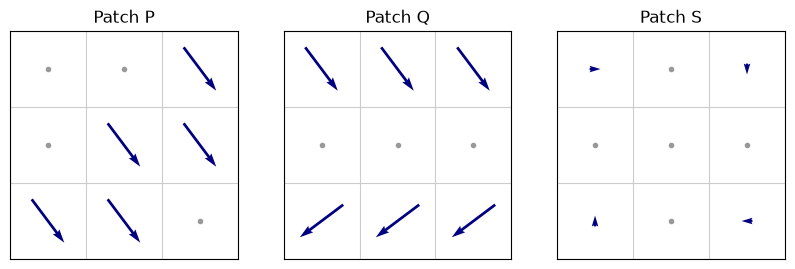

In [7]:
# Run to draw the three patches of Question 3(a).
patches = {   # (column, row) -> (Ix, Iy)
    "Patch P": {(0, 2): (3, 4), (1, 1): (3, 4), (2, 0): (3, 4), (1, 2): (3, 4), (2, 1): (3, 4)},
    "Patch Q": {(0, 0): (3, 4), (1, 0): (3, 4), (2, 0): (3, 4),
                (0, 2): (-4, 3), (1, 2): (-4, 3), (2, 2): (-4, 3)},
    "Patch S": {(0, 0): (1, 0), (2, 0): (0, 1), (0, 2): (0, -1), (2, 2): (-1, 0)},
}
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
for ax, (name, g) in zip(axes, patches.items()):
    for col in range(3):
        for row in range(3):
            gx, gy = g.get((col, row), (0, 0))
            if gx == 0 and gy == 0:
                ax.plot(col + 0.5, row + 0.5, "o", color="0.6", ms=3)
            else:
                ax.quiver(col + 0.5, row + 0.5, gx, gy, angles="xy", scale_units="xy", scale=7, pivot="middle",
                          color="navy", width=0.012)
    ax.set_xlim(0, 3); ax.set_ylim(3, 0)          # y axis points down
    ax.set_xticks(range(4)); ax.set_yticks(range(4)); ax.grid(True, color="0.8")
    ax.tick_params(labelbottom=False, labelleft=False, length=0)
    ax.set_aspect("equal"); ax.set_title(name)
plt.show()

*Note that $R$ is a sum over the pixels of the window, so it depends only on which gradient values occur and how often, and not on where in the window they sit. The arrangements drawn above are therefore one plausible choice out of many: in $P$ the five equal gradients lie along a single edge running through the window, in $Q$ the window contains two edge fragments whose gradients are perpendicular, and in $S$ the four gradients point in unrelated directions and are five times shorter than those of $P$ and $Q$.*

For each patch, write down the three sums $\sum I_x^{2}$, $\sum I_y^{2}$, $\sum I_xI_y$ and hence the matrix $R$; compute $\lambda_1\ge\lambda_2$ and the eigenvectors; and classify the patch as corner, edge or flat. For the edge patch, state the orientation of the edge and check that it agrees with your eigenvector. *(Keep these three matrices; Question 4 reuses them.)*

**Solution 3(a).**

In each case $R=\begin{bmatrix}\sum I_x^{2} & \sum I_xI_y\\ \sum I_xI_y & \sum I_y^{2}\end{bmatrix}$.

*Patch $P$.* Each of the five non-zero pixels adds $I_x^{2}=9$, $I_y^{2}=16$, $I_xI_y=12$. So $\sum I_x^{2}=45$, $\sum I_y^{2}=80$, $\sum I_xI_y=60$, and $R_P=\begin{bmatrix}45&60\\60&80\end{bmatrix}$, with $\operatorname{tr}=125$ and $\det=45\cdot80-60^{2}=0$. So $\lambda_1=125$, $\lambda_2=0$: an **edge**. The eigenvector of $\lambda_1$ is $(3,4)/5$, the gradient direction, which points across the edge. The eigenvector of $\lambda_2=0$ is $(-4,3)/5$, so the edge runs along $(-4,3)$, at about $143.1^{\circ}$ from the $x$-axis. Moving along the edge causes no change, as expected.

*Patch $Q$.* The three $(3,4)$ pixels add $3\times(9,16,12)$ and the three $(-4,3)$ pixels add $3\times(16,9,-12)$. So $\sum I_x^{2}=75$, $\sum I_y^{2}=75$, $\sum I_xI_y=0$, and $R_Q=\begin{bmatrix}75&0\\0&75\end{bmatrix}$. $\lambda_1=\lambda_2=75$, and every direction is an eigenvector. This is a **corner**: two perpendicular gradient directions, equally strong, so every shift changes the patch.

*Patch $S$.* $\sum I_x^{2}=\sum I_y^{2}=2$, $\sum I_xI_y=0$, so $R_S=\begin{bmatrix}2&0\\0&2\end{bmatrix}$, $\lambda_1=\lambda_2=2$, and every direction is an eigenvector. The eigenvalue ratio is the same as for $Q$, but the values are $37.5$ times smaller. So this is a **flat** patch with only weak variation. Lesson: the ratio alone is not enough, the strength matters too. That is why we need a threshold.

In [8]:
# Check for 3(a) and 4(a).
grads = {
    "P": [(3, 4)] * 5 + [(0, 0)] * 4,
    "Q": [(3, 4)] * 3 + [(-4, 3)] * 3 + [(0, 0)] * 3,
    "S": [(1, 0), (0, 1), (-1, 0), (0, -1)] + [(0, 0)] * 5,
}
Rs, Ms = {}, {}
for name, g in grads.items():
    g = np.array(g, float)
    R = g.T @ g                      # [[sum Ix^2, sum IxIy], [sum IxIy, sum Iy^2]]
    lam, vec = np.linalg.eigh(R)
    Rs[name] = R
    Ms[name] = np.linalg.det(R) - 0.04 * np.trace(R) ** 2
    print(f"R_{name} = {R.tolist()}, lambda = {lam[::-1].round(3)}, v1 = {vec[:, 1].round(3)}, "
          f"det = {np.linalg.det(R):.1f}, tr = {np.trace(R):.0f}, M = {Ms[name]:.2f}")
assert np.allclose(Rs["P"], [[45, 60], [60, 80]]) and np.allclose(Rs["Q"], 75 * np.eye(2)) and np.allclose(Rs["S"], 2 * np.eye(2))
assert np.allclose([Ms["P"], Ms["Q"], Ms["S"]], [-625, 4725, 3.36])
print(f"M_S / M_Q = {Ms['S'] / Ms['Q']:.2e};  edge direction of P at {np.degrees(np.arctan2(3, -4)):.1f} deg")

R_P = [[45.0, 60.0], [60.0, 80.0]], lambda = [125.   0.], v1 = [0.6 0.8], det = 0.0, tr = 125, M = -625.00
R_Q = [[75.0, 0.0], [0.0, 75.0]], lambda = [75. 75.], v1 = [0. 1.], det = 5625.0, tr = 150, M = 4725.00
R_S = [[2.0, 0.0], [0.0, 2.0]], lambda = [2. 2.], v1 = [0. 1.], det = 4.0, tr = 4, M = 3.36
M_S / M_Q = 7.11e-04;  edge direction of P at 143.1 deg


**(b) The two Gaussians.** **[5]**

Lecture 04 introduced two distinct Gaussians: $\sigma_s$, which smooths the image before differentiation, and $\sigma_w$, which weights the window.

1. State the purpose of each, and explain why they are independent parameters rather than one.
2. Let the window shrink to a single pixel, so that $R$ is built from one gradient $(I_x,I_y)$ alone. Compute $\det R$ and $\operatorname{tr} R$ in this case, and hence the Harris response $M=\det R-\kappa\,\operatorname{tr}^2R$. State what the detector now reports everywhere in every image, and what this tells you about where cornerness resides.

**Solution 3(b).**

1. $\sigma_s$ smooths the image before taking derivatives, because differencing amplifies noise. It decides how reliable each gradient is. $\sigma_w$ decides how big the patch is, and weights its pixels smoothly so that the response does not jump when a pixel enters or leaves the window. These answer two different questions (how good is each gradient, and how big is the structure), so they are separate parameters. Typical values (Lecture 04) are $\sigma_s\approx2$ and $\sigma_w\approx1$, and they are not tied to each other. Lecture 06 later turns $\sigma_w$ into a scale that we search over.

2. With one pixel, $R=\begin{bmatrix}I_x^{2}&I_xI_y\\ I_xI_y&I_y^{2}\end{bmatrix}$, so $\det R=I_x^{2}I_y^{2}-(I_xI_y)^{2}=0$ always, and $\operatorname{tr} R=I_x^{2}+I_y^{2}$. Hence
$$M=0-\kappa\,\operatorname{tr}^{2}R=-\kappa\,(I_x^{2}+I_y^{2})^{2}\;\le\;0\quad\text{everywhere.}$$
The detector finds **no corner in any image**, and its most negative values are at the strongest edges. Lesson: a single pixel cannot be a corner. One gradient shows only one direction of change. Two directions appear only when we combine the gradients of a neighbourhood. So the window is part of what a corner *is*, not just an implementation detail.

---
## Question 4. The Harris response and sub-pixel localisation  [20 marks]

**(a) The response on the three patches.** **[5]**

Using $R_P,R_Q,R_S$ from Question 3(a), compute $M=\det R-\kappa\operatorname{tr}^{2}R$ for $\kappa=0.04$ and tabulate $\det R$, $\operatorname{tr} R$ and $M$. The flat patch gives $M>0$. State precisely what the sign of $M$ does and does not tell you, and quote the ratio $M_S/M_Q$ in support of your answer.

**Solution 4(a).**

| Patch | $\det R$ | $\operatorname{tr} R$ | $M\ (\kappa=0.04)$ | Verdict |
|---|---|---|---|---|
| $P$ (edge) | $0$ | $125$ | $-625.0$ | edge (strongly negative) |
| $Q$ (corner) | $5625$ | $150$ | $+4725.0$ | corner |
| $S$ (flat) | $4$ | $4$ | $+3.36$ | flat, although $M>0$ |

The sign of $M$ tells you about *shape*, not *strength*. $M<0$ means the patch is elongated (an edge). $M>0$ means it is fairly round (not too elongated). Multiplying $R$ by any positive number scales $\det R$ and $\operatorname{tr}^2 R$ by the same factor, so the sign does not change. The flat patch is round but very weak, so $M>0$. Evidence: $M_S/M_Q = 3.36/4725 = 7.1\times10^{-4}$, i.e. $0.07\%$. This gap of more than three orders of magnitude is what the relative threshold $T=0.01\max M$ uses. The sign alone would mark every flat region as a corner.

**(b) The meaning of $\kappa$.** **[5]**

Let $r=\lambda_1/\lambda_2\ge1$ measure the elongation of the patch.

1. Starting from $M=\lambda_1\lambda_2-\kappa(\lambda_1+\lambda_2)^{2}$, divide by $\lambda_2^{2}$ and show that $M>0$ is equivalent to $\kappa\,r^{2}-(1-2\kappa)\,r+\kappa<0$. Solve this quadratic for $\kappa=0.04$ and for $\kappa=0.06$, and state the largest $r$ accepted in each case. Conclude that $\kappa$ acts as a threshold on the elongation.
2. SIFT rejects a keypoint when its curvature ratio exceeds $r_{\max}=10$ (see the Lecture 07 slides). Compare this with your answer to (1), and state in one or two sentences what design decision $\kappa$ and $r_{\max}$ are two ways of expressing.

**Solution 4(b).**

1. $M>0$ means $\lambda_1\lambda_2>\kappa(\lambda_1+\lambda_2)^{2}$. Divide by $\lambda_2^{2}>0$ and put $r=\lambda_1/\lambda_2$: $r>\kappa(r+1)^{2}$, i.e. $\kappa r^{2}-(1-2\kappa)r+\kappa<0$. The roots are $r=\dfrac{(1-2\kappa)\pm\sqrt{1-4\kappa}}{2\kappa}$. For $\kappa=0.04$: $r\in(0.0436,\;22.96)$. For $\kappa=0.06$: $r\in(0.0685,\;14.60)$. The lower root is $1/$(upper root), because swapping $\lambda_1$ and $\lambda_2$ changes nothing. With $r\ge1$: $M>0$ exactly when $r<\mathbf{22.96}$ ($\kappa=0.04$) or $r<\mathbf{14.60}$ ($\kappa=0.06$). A larger $\kappa$ demands a rounder patch, so $\kappa$ is a threshold on elongation.

2. SIFT keeps $r<10$. Harris keeps $r<23$ ($\kappa=0.04$) or $r<14.6$ ($\kappa=0.06$). Both express the same decision: how elongated can a structure be before we stop trusting its position along the long direction? SIFT sets the limit on $r$ directly. Harris hides it inside one signed score that both classifies and ranks. SIFT is the stricter of the two.

In [9]:
# Check for 4(b).
for kappa, upper in ((0.04, 22.96), (0.06, 14.60)):
    roots = np.sort(np.roots([kappa, -(1 - 2 * kappa), kappa]))
    print(f"kappa = {kappa}: M > 0 for r in ({roots[0]:.4f}, {roots[1]:.2f})")
    assert round(roots[1], 2) == upper and np.isclose(roots[0] * roots[1], 1)

kappa = 0.04: M > 0 for r in (0.0436, 22.96)
kappa = 0.06: M > 0 for r in (0.0685, 14.60)


**(c) Invariance.** **[5]**

1. For $I\to aI+b$ with $a>0$, derive how the entries of $R$, the eigenvalues $\lambda_i$ and the response $M$ transform. State the consequence for a fixed threshold $T$ and give the standard remedy.
2. Rotate the image. The gradient at a corresponding point is the original gradient rotated by the same angle. Explain why the eigenvalues of $R$, and therefore $M$, are unchanged, and state the one assumption about the window that this argument requires. Do typical implementations satisfy it?
3. Explain in words why the same argument fails for a change of scale, in which the image is magnified by a factor $c$ while the window remains a fixed number of pixels.

**Solution 4(c).**

1. Differentiation removes $b$, so $I_x\to aI_x$ and $I_y\to aI_y$. Each entry of $R$ is a product of two gradient components, so $R\to a^{2}R$. Hence $\lambda_i\to a^{2}\lambda_i$, $\det R\to a^{4}\det R$, $\operatorname{tr}^{2}R\to a^{4}\operatorname{tr}^{2}R$, and $M\to a^{4}M$. The signs and the ranking of corners do not change, but a **fixed** threshold $T$ breaks: doubling the brightness multiplies every response by $16$, so a threshold tuned on one image passes almost every pixel of the other. Remedy: a relative threshold $T=t\cdot\max M$ with $t\approx0.01$, or normalise the image first.

2. Rotating the image by $Q$ turns each gradient $\mathbf g$ into $Q\mathbf g$, so $R\to QRQ^{\top}$. This matrix has the same eigenvalues; only the eigenvectors turn with the image. $M$ depends only on the eigenvalues ($\det R=\lambda_1\lambda_2$, $\operatorname{tr} R=\lambda_1+\lambda_2$), so $M$ does not change.

3. After a rotation, the window still covers the same part of the scene, so it holds the same gradients, just turned. After magnifying by $c$, a window of fixed pixel size covers a part of the scene $c$ times smaller, so it holds *different* gradients.

**(d) Sub-pixel refinement by hand.** **[5]**

Near a detected maximum at $(x_c,y_c)$ the Harris response map takes the values

| | $x-1$ | $x$ | $x+1$ |
|:-:|:-:|:-:|:-:|
| $y-1$ | 0.20 | 0.55 | 0.45 |
| $y$ | 0.32 | **1.00** | 0.86 |
| $y+1$ | 0.18 | 0.60 | 0.52 |

1. Using the kernels of Lecture 05, namely $f_x:\tfrac12[1\ 0\ {-}1]$, $f_{xx}:[1\ {-}2\ 1]$ and $f_{xy}:\tfrac14\begin{bmatrix}1&0&-1\\0&0&0\\-1&0&1\end{bmatrix}$, compute $\nabla f$ and $H$, and solve $\Delta=-H^{-1}\nabla f$.
2. Verify from the signs of $\operatorname{tr} H$ and $\det H$ that the refined point is a maximum and not a saddle.

**Solution 4(d).**

1. $f_x=\tfrac12(0.86-0.32)=0.27$, $f_y=\tfrac12(0.60-0.55)=0.025$, $f_{xx}=0.32-2(1.00)+0.86=-0.82$, $f_{yy}=0.55-2(1.00)+0.60=-0.85$, $f_{xy}=\tfrac14(0.52-0.18-0.45+0.20)=0.0225$.

$H=\begin{bmatrix}-0.82&0.0225\\0.0225&-0.85\end{bmatrix}$, $\det H=0.82\cdot0.85-0.0225^2=0.696494$, and
$$\Delta=-H^{-1}\nabla f=\frac{1}{\det H}\begin{bmatrix}0.85&0.0225\\0.0225&0.82\end{bmatrix}\begin{bmatrix}0.27\\0.025\end{bmatrix}=\frac{1}{0.696494}\begin{bmatrix}0.2301\\0.0266\end{bmatrix},\qquad \boxed{\ \Delta=(+0.3303,\;+0.0382)\ }$$
so $(x^{\ast},y^{\ast})=(x_c+0.3303,\ y_c+0.0382)$. (Sign convention: convolving with $\tfrac12[1\ 0\ {-}1]$ gives the central difference $\tfrac12[f(x{+}1)-f(x{-}1)]$.)

2. $\operatorname{tr} H=-1.67<0$ and $\det H=0.6965>0$, so both eigenvalues are negative ($-0.862$ and $-0.808$): a true **maximum**. If $\det H$ were negative, the two curvatures would have opposite signs and the point would be a saddle.

In [10]:
# Check for 4(d). Rows are y-1, y, y+1 and columns are x-1, x, x+1.
f = np.array([[0.20, 0.55, 0.45],
              [0.32, 1.00, 0.86],
              [0.18, 0.60, 0.52]])
fx = (f[1, 2] - f[1, 0]) / 2
fy = (f[2, 1] - f[0, 1]) / 2
fxx = f[1, 0] - 2 * f[1, 1] + f[1, 2]
fyy = f[0, 1] - 2 * f[1, 1] + f[2, 1]
fxy = (f[2, 2] - f[2, 0] - f[0, 2] + f[0, 0]) / 4
H = np.array([[fxx, fxy], [fxy, fyy]])
Delta = -np.linalg.solve(H, [fx, fy])
print(f"grad = ({fx}, {fy}), H = {H.tolist()}, det = {np.linalg.det(H):.6f}, Delta = {Delta.round(4)}, "
      f"eig = {np.linalg.eigvalsh(H).round(3)}")
assert np.allclose(Delta, [0.3303, 0.0382], atol=5e-5) and np.all(np.linalg.eigvalsh(H) < 0)

grad = (0.27, 0.024999999999999967), H = [[-0.82, 0.022500000000000006], [0.022500000000000006, -0.85]], det = 0.696494, Delta = [0.3303 0.0382], eig = [-0.862 -0.808]


---
## Question 5. Scale space and scale normalisation  [10 marks]

**(a) Why the factor $\sigma^{2}$.** **[5]**

1. For an ideal step $I(x)=u(x-x_0)$, derive the LoG response $R_\sigma(x)=u\ast \tfrac{d^{2}G_\sigma}{dx^{2}}$, show that its extrema lie at $x=x_0\pm\sigma$, and evaluate $R_\sigma(x_0\pm\sigma)$.
2. Hence explain why the unnormalised LoG response cannot be compared across scales, and why multiplying by $\sigma^{2}$ is the exact correction rather than merely a convenient one.

**Solution 5(a).**

1. Move one derivative onto the step: $u\ast\frac{d^{2}G_\sigma}{dx^{2}}=\frac{du}{dx}\ast\frac{dG_\sigma}{dx}=\delta(x{-}x_0)\ast\frac{dG_\sigma}{dx}=\frac{dG_\sigma}{dx}(x-x_0)$. So
$$R_\sigma(x)=-\frac{1}{\sqrt{2\pi}\,\sigma^{3}}(x-x_0)\,e^{-(x-x_0)^{2}/2\sigma^{2}} .$$
Setting $R'_\sigma=0$ gives $1-(x-x_0)^{2}/\sigma^{2}=0$, so $x=x_0\pm\sigma$. There, $R_\sigma(x_0\pm\sigma)=\mp\frac{1}{\sqrt{2\pi}\,\sigma^{2}}e^{-1/2}$.

2. For the same step, the peak falls like $1/\sigma^{2}$. So raw responses at different scales cannot be compared: small $\sigma$ always wins, and $\arg\max_\sigma$ is always the smallest $\sigma$ in the stack, whatever the image. Multiplying by $\sigma^{2}$ makes the peak $\mp\frac{1}{\sqrt{2\pi}}e^{-1/2}$, the same for every $\sigma$. So any change with $\sigma$ that is left comes from the image, not from the filter. Any other power of $\sigma$ would still favour small or large scales.

In [11]:
# Check for 5(a): numerically, the LoG response of a unit step peaks at x0 +- sigma with height ~ 1/sigma^2.
from scipy.special import erf
for sigma in (1.0, 2.0, 4.0):
    x = np.linspace(-6 * sigma, 6 * sigma, 20001)
    R = -x / (np.sqrt(2 * np.pi) * sigma ** 3) * np.exp(-x ** 2 / (2 * sigma ** 2))   # d/dx G, i.e. step * G''
    xm = x[np.argmin(R)]
    print(f"sigma = {sigma}: extremum at x = {xm:+.3f}, sigma^2 * peak = {sigma ** 2 * R.min():.5f}")
    assert np.isclose(abs(xm), sigma, atol=1e-2)
    assert np.isclose(sigma ** 2 * R.min(), -np.exp(-0.5) / np.sqrt(2 * np.pi), atol=1e-6)

sigma = 1.0: extremum at x = +1.000, sigma^2 * peak = -0.24197
sigma = 2.0: extremum at x = +2.000, sigma^2 * peak = -0.24197
sigma = 4.0: extremum at x = +4.001, sigma^2 * peak = -0.24197


**(b) What a detected $\sigma$ means.** **[5]**

1. Using the zero set of the 2-D LoG, derive $r=\sqrt2\,\sigma$ for a binary disc of radius $r$, and state the geometric picture in one sentence.

**Solution 5(b).**

1. Up to a positive constant, $\nabla^{2} G(x,y)=\frac{x^{2}+y^{2}-2\sigma^{2}}{\sigma^{4}}e^{-(x^{2}+y^{2})/2\sigma^{2}}$. The exponential is never zero, so the zero set is the circle $x^{2}+y^{2}=2\sigma^{2}$, of radius $\sqrt2\,\sigma$. The response is largest (in magnitude) when the central lobe exactly covers the disc and the outer ring, of opposite sign, lies on the background. That happens when $\sqrt2\,\sigma=r$, i.e. $r=\sqrt2\,\sigma$. In one sentence: the detected scale is the one where the filter's zero circle sits on the boundary of the blob.

---
# Part B - Programming  [35 marks]

## Question 6. Canny edge detector implementation  [35 marks]

Implement the four stages yourself: derivative-of-Gaussian gradients, magnitude and orientation, non-maximum suppression with interpolated neighbours, and hysteresis with 8-connected linking. Show four panels: $\lVert\nabla G\rVert$, the map after thresholding at $T_1$ only, the map after non-maximum suppression, and the final result. Compare your output with `cv2.Canny` on the same image. Report the fraction of your edge pixels lying within $1$ px of a `cv2.Canny` edge pixel, and account for at least two systematic differences. Note that `cv2.Canny` uses a fixed $3\times3$ Sobel operator and by default the $L_1$ magnitude $|G_x|+|G_y|$; verify the effect of the `L2gradient` flag.

**Data.** The setup cell downloaded `assignment2_data/building.jpg` (a photograph with long straight edges) and `assignment2_data/scene.png` (a synthetic image with ideal step edges and exact corners, useful for debugging). Develop on `scene.png`, then report on `building.jpg`. You may additionally use an image of your own (upload it with the file browser on the left).

**Rules.** You may use NumPy, SciPy and OpenCV for image I/O and for applying a kernel that *you* have built (for example `scipy.ndimage.convolve1d` or `cv2.sepFilter2D`). The four stages themselves must be your own code: do not use `cv2.Canny` (except for the comparison), `cv2.Sobel`, `cv2.GaussianBlur`, `skimage.feature.canny`, or a library connected-components routine for the hysteresis. Vectorised NumPy is expected where it is natural; a loop over the edge pixels in the linking step is fine.

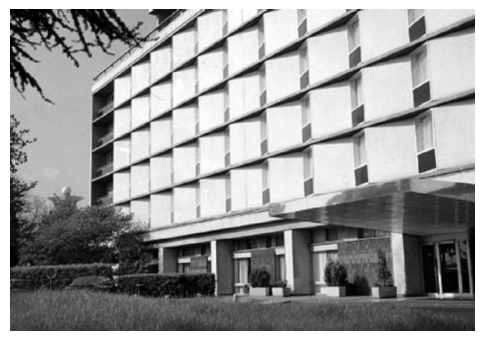

(354, 512) 0.0 255.0


In [12]:
from scipy import ndimage

img_bgr = cv2.imread(f"{DATA}/building.jpg")          # change the file name to try another image
img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY).astype(np.float64)
plt.figure(figsize=(6, 5)); plt.imshow(img, cmap="gray"); plt.axis("off"); plt.show()
print(img.shape, img.min(), img.max())

### Stage 1 and 2: derivative-of-Gaussian gradients, magnitude and orientation

In [13]:
def gaussian_kernels(sigma):
    # The sampled 1-D Gaussian g and its derivative dg on x = -r..r with r = ceil(3 sigma).
    # g sums to 1; dg is scaled so that correlating it with a unit ramp returns slope 1.
    r = int(np.ceil(3 * sigma))
    x = np.arange(-r, r + 1, dtype=float)
    g = np.exp(-x ** 2 / (2 * sigma ** 2))
    g /= g.sum()
    dg = -x / sigma ** 2 * g
    dg /= -(dg * x).sum()
    return g, dg


def gradients(img, sigma):
    # Separable derivative of Gaussian: smooth across, differentiate along. convolve1d flips the
    # kernel, so pass dg reversed to correlate (positive Ix for intensity increasing with x).
    g, dg = gaussian_kernels(sigma)
    Ix = ndimage.convolve1d(ndimage.convolve1d(img, g, axis=0, mode="reflect"), dg[::-1], axis=1, mode="reflect")
    Iy = ndimage.convolve1d(ndimage.convolve1d(img, g, axis=1, mode="reflect"), dg[::-1], axis=0, mode="reflect")
    return Ix, Iy


def magnitude_orientation(Ix, Iy):
    return np.hypot(Ix, Iy), np.arctan2(Iy, Ix)

### Stage 3: non-maximum suppression with interpolated neighbours

In [14]:
def non_max_suppression(mag, Ix, Iy):
    # Compare every pixel with the bilinearly interpolated magnitude one pixel forwards and one
    # pixel backwards along its unit gradient direction; keep it only if it is not smaller than either.
    h, w = mag.shape
    ys, xs = np.mgrid[0:h, 0:w].astype(float)
    m = np.maximum(mag, 1e-12)
    ux, uy = Ix / m, Iy / m

    def bilinear(x, y):
        x = np.clip(x, 0, w - 1 - 1e-6)
        y = np.clip(y, 0, h - 1 - 1e-6)
        X, Y = np.floor(x).astype(int), np.floor(y).astype(int)
        dx, dy = x - X, y - Y
        return ((1 - dx) * (1 - dy) * mag[Y, X] + dx * (1 - dy) * mag[Y, X + 1]
                + (1 - dx) * dy * mag[Y + 1, X] + dx * dy * mag[Y + 1, X + 1])

    keep = (mag >= bilinear(xs + ux, ys + uy)) & (mag >= bilinear(xs - ux, ys - uy)) & (mag > 0)
    keep[0, :] = keep[-1, :] = keep[:, 0] = keep[:, -1] = False
    return np.where(keep, mag, 0.0)

### Stage 4: hysteresis with 8-connected linking

In [15]:
def hysteresis(nms, T1, T2):
    # Flood fill from every strong pixel through 8-connected weak pixels (depth-first, explicit stack).
    weak = nms >= T1
    edges = nms >= T2
    h, w = nms.shape
    stack = list(zip(*np.nonzero(edges)))
    while stack:
        y, x = stack.pop()
        for dy in (-1, 0, 1):
            for dx in (-1, 0, 1):
                yy, xx = y + dy, x + dx
                if 0 <= yy < h and 0 <= xx < w and weak[yy, xx] and not edges[yy, xx]:
                    edges[yy, xx] = True
                    stack.append((yy, xx))
    return edges


def my_canny(img, sigma, T1, T2):
    # Given: runs the four stages and returns every intermediate map for the figures.
    Ix, Iy = gradients(img, sigma)
    mag, theta = magnitude_orientation(Ix, Iy)
    nms = non_max_suppression(mag, Ix, Iy)
    edges = hysteresis(nms, T1, T2)
    return dict(Ix=Ix, Iy=Iy, mag=mag, theta=theta, nms=nms, edges=edges)

### Results: the four panels

Choose $\sigma$, $T_1$ and $T_2$ for your image and justify the choice in the answer cell at the end.

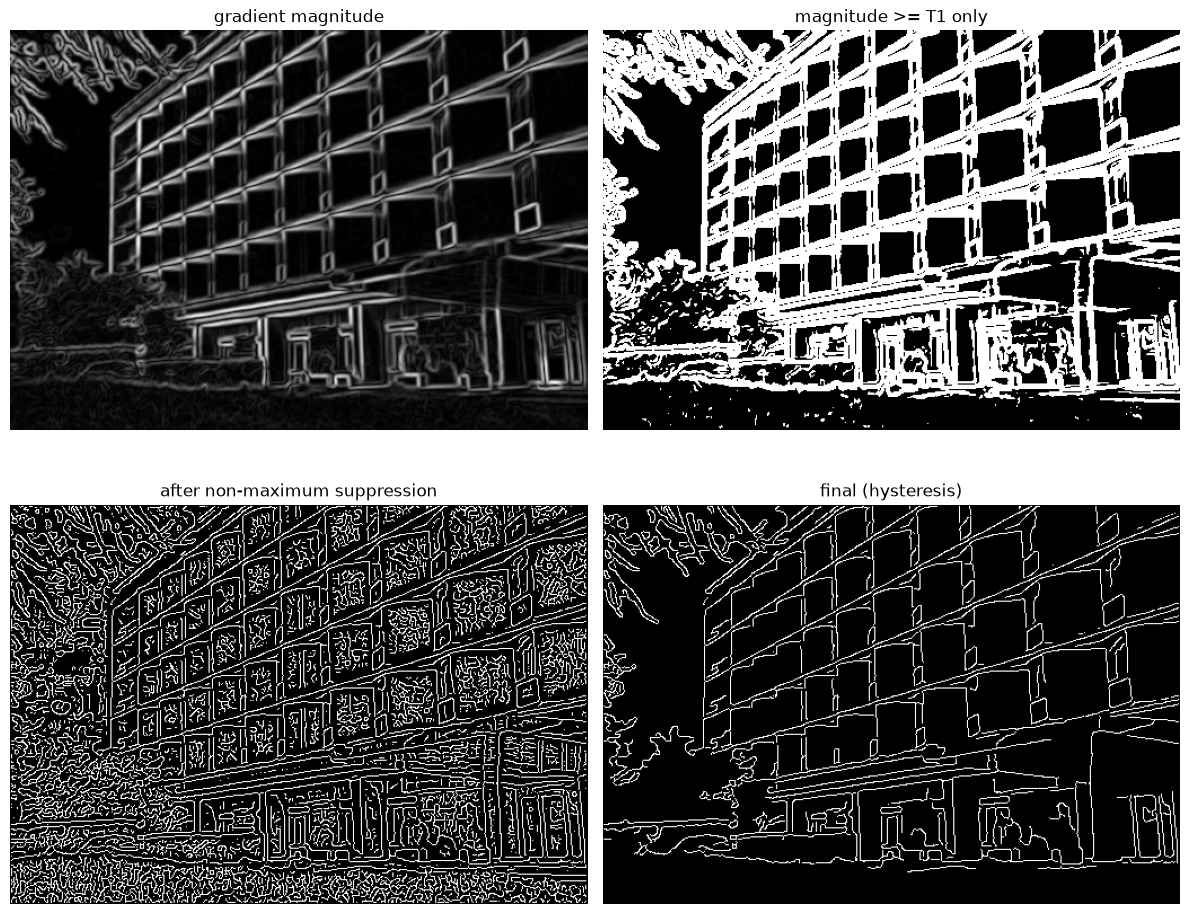

edge pixels: 14795


In [16]:
SIGMA, T1, T2 = 1.4, 6.0, 15.0      # grey levels per pixel of the smoothed image

out = my_canny(img, SIGMA, T1, T2)
panels = [("gradient magnitude", out["mag"]),
          ("magnitude >= T1 only", out["mag"] >= T1),
          ("after non-maximum suppression", out["nms"] > 0),
          ("final (hysteresis)", out["edges"])]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (title, im) in zip(axes.ravel(), panels):
    ax.imshow(im, cmap="gray"); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()
print("edge pixels:", int(out["edges"].sum()))

### Comparison with `cv2.Canny`

`cv2.Canny` works on the unsmoothed 8-bit image with a $3\times3$ Sobel operator, so its thresholds are on a different scale from yours; choose `lo`, `hi` so that the two detectors report a comparable number of edge pixels. Smooth the input with your own Gaussian first if you want a fairer comparison, and say whether you did.

cv2.Canny L1: 30255 edge pixels; fraction of mine within 1 px: 0.9996620479891856
cv2.Canny L2: 26928 edge pixels; fraction of mine within 1 px: 0.9996620479891856


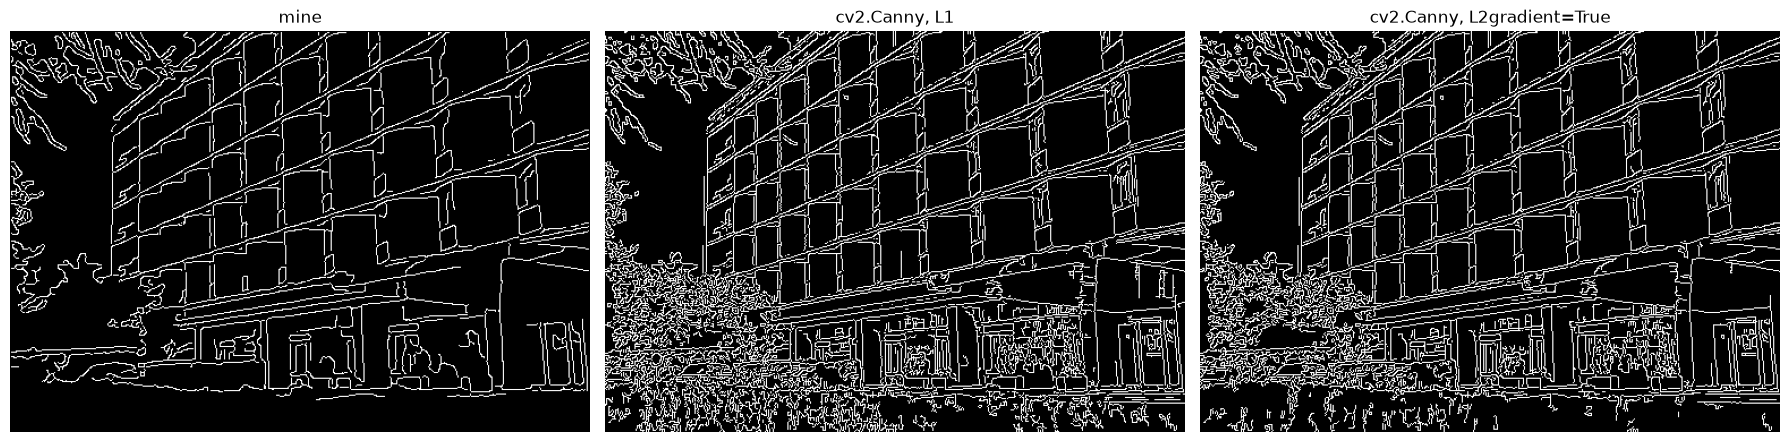

In [17]:
def fraction_within_1px(mine, ref):
    # Fraction of the True pixels of `mine` that lie within 1 px (8-neighbourhood) of a True pixel of `ref`.
    near = ndimage.binary_dilation(ref, structure=np.ones((3, 3), bool))
    return (mine & near).sum() / max(mine.sum(), 1)


lo, hi = 8 * T1, 8 * T2               # the 3x3 Sobel returns 8x the slope of a ramp, so these match T1, T2
img_u8 = img.astype(np.uint8)
cv_l1 = cv2.Canny(img_u8, lo, hi, L2gradient=False) > 0
cv_l2 = cv2.Canny(img_u8, lo, hi, L2gradient=True) > 0

for name, ref in (("cv2.Canny L1", cv_l1), ("cv2.Canny L2", cv_l2)):
    print(f"{name}: {int(ref.sum())} edge pixels; fraction of mine within 1 px: "
          f"{fraction_within_1px(out['edges'], ref)}")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (title, im) in zip(axes, (("mine", out["edges"]), ("cv2.Canny, L1", cv_l1), ("cv2.Canny, L2gradient=True", cv_l2))):
    ax.imshow(im, cmap="gray"); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

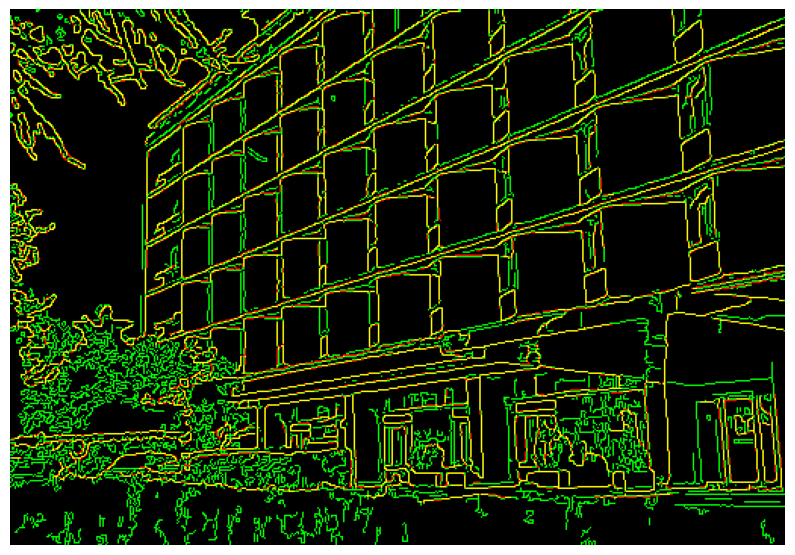

In [18]:
# Overlay: yours in red, cv2.Canny (L2) in green, both in yellow.
overlay = np.zeros(img.shape + (3,))
overlay[..., 0] = out["edges"]
overlay[..., 1] = cv_l2
plt.figure(figsize=(10, 8)); plt.imshow(overlay); plt.axis("off"); plt.show()

### Report for Question 6

Answer in the cell below:

1. The image(s) you used and your choice of $\sigma$, $T_1$, $T_2$ (and `lo`, `hi` for `cv2.Canny`), with a short justification.
2. The fraction of your edge pixels lying within 1 px of a `cv2.Canny` edge pixel, for both settings of `L2gradient`.
3. At least two systematic differences between your output and `cv2.Canny`, each explained by a specific difference between the two implementations, with a pointer to where it is visible in the figures.
4. What changes when `L2gradient=True`, and why.

In [19]:
# Extra (key): the same comparison when cv2.Canny is given the image smoothed with our own Gaussian,
# and the L1 / L2 magnitudes along a diagonal and an axis-aligned step.
g, _ = gaussian_kernels(SIGMA)
smooth = ndimage.convolve1d(ndimage.convolve1d(img, g, axis=0), g, axis=1)
sm_u8 = np.clip(np.round(smooth), 0, 255).astype(np.uint8)
for flag in (False, True):
    ref = cv2.Canny(sm_u8, lo, hi, L2gradient=flag) > 0
    print(f"smoothed input, L2gradient={flag}: {int(ref.sum())} edge pixels, fraction of mine within 1 px "
          f"{fraction_within_1px(out['edges'], ref):.3f}, fraction of cv2's within 1 px of mine "
          f"{fraction_within_1px(ref, out['edges']):.3f}")

theta_edge = out["theta"][out["edges"]]
diag = np.abs(np.sin(2 * theta_edge)) > np.sin(np.deg2rad(60))          # gradient within 15 deg of a diagonal
print(f"fraction of my edge pixels with a near-diagonal gradient: {diag.mean():.3f}")
for name, ref in (("L1", cv_l1), ("L2", cv_l2)):
    print(f"{name}: extra cv2 pixels (not within 1 px of mine): {int((ref & ~ndimage.binary_dilation(out['edges'], np.ones((3, 3), bool))).sum())}")

smoothed input, L2gradient=False: 15768 edge pixels, fraction of mine within 1 px 0.978, fraction of cv2's within 1 px of mine 0.947
smoothed input, L2gradient=True: 14714 edge pixels, fraction of mine within 1 px 0.952, fraction of cv2's within 1 px of mine 0.987
fraction of my edge pixels with a near-diagonal gradient: 0.207
L1: extra cv2 pixels (not within 1 px of mine): 13692
L2: extra cv2 pixels (not within 1 px of mine): 10403


---
*End of Assignment 2.*